In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Use relative paths so it works on any machine
diabetes_df = pd.read_csv('../data/raw/diabetes.csv')
heart_df = pd.read_csv('../data/raw/heart.csv')

In [3]:
print("=== DIABETES DATASET ===")
print(diabetes_df.shape)       # rows and columns
print(diabetes_df.head())      # first 5 rows
print(diabetes_df.info())      # column types and nulls
print(diabetes_df.describe())  # stats summary

print("\n=== HEART DISEASE DATASET ===")
print(heart_df.shape)
print(heart_df.head())
print(heart_df.info())
print(heart_df.describe())

=== DIABETES DATASET ===
(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  


In [4]:
print("Diabetes missing values:\n", diabetes_df.isnull().sum())
print("\nHeart missing values:\n", heart_df.isnull().sum())

Diabetes missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Heart missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


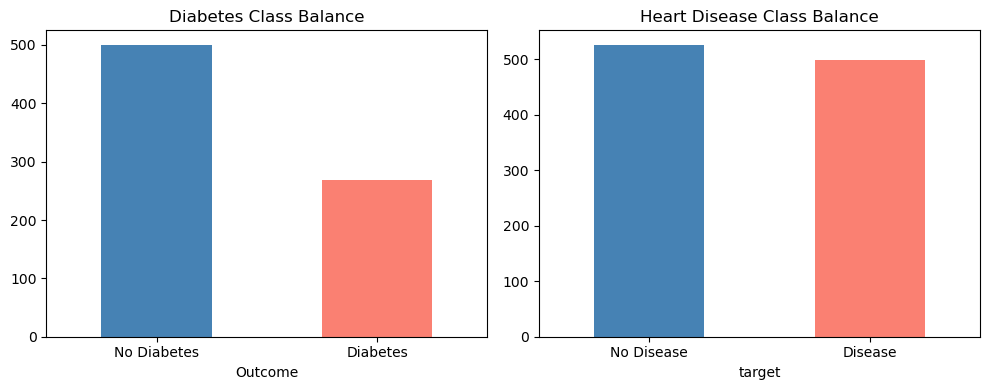

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

diabetes_df['Outcome'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','salmon'])
axes[0].set_title('Diabetes Class Balance')
axes[0].set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)

heart_df['target'].value_counts().plot(kind='bar', ax=axes[1], color=['steelblue','salmon'])
axes[1].set_title('Heart Disease Class Balance')
axes[1].set_xticklabels(['No Disease', 'Disease'], rotation=0)

plt.tight_layout()
plt.savefig('../results/figures/class_balance.png')
plt.show()

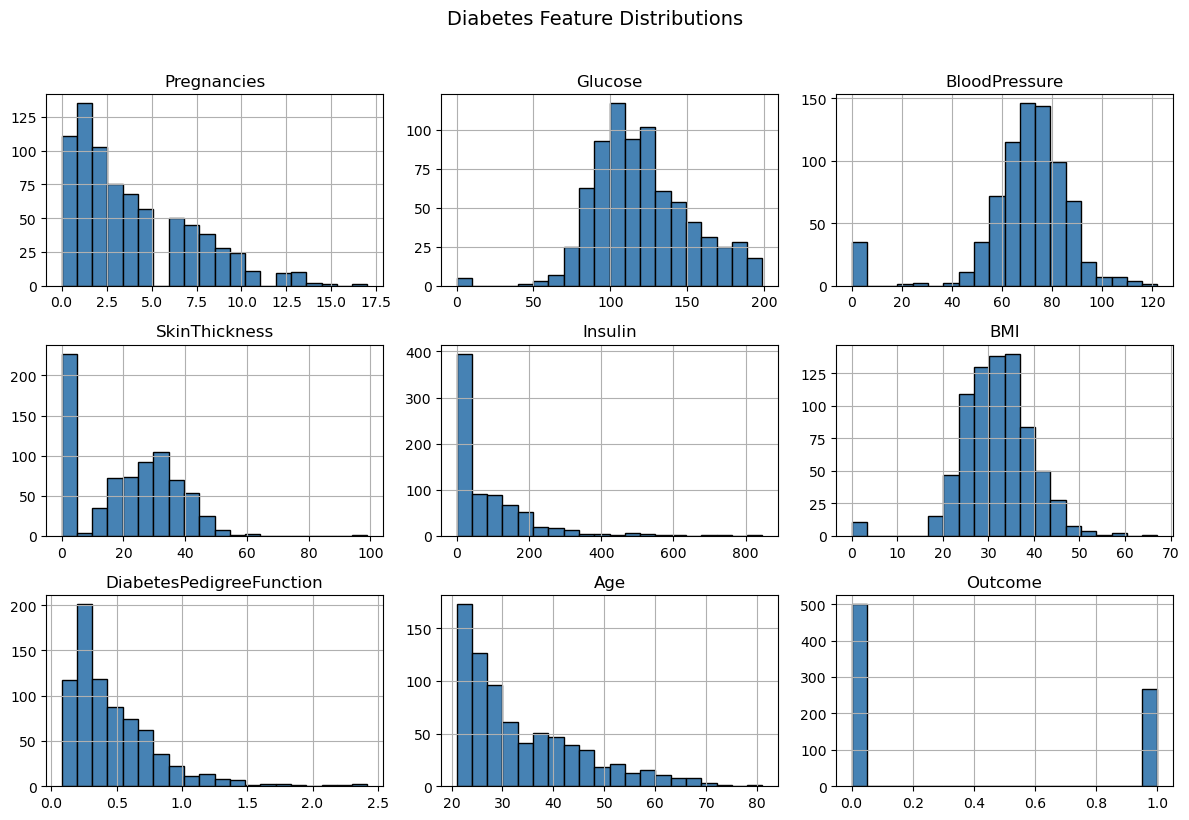

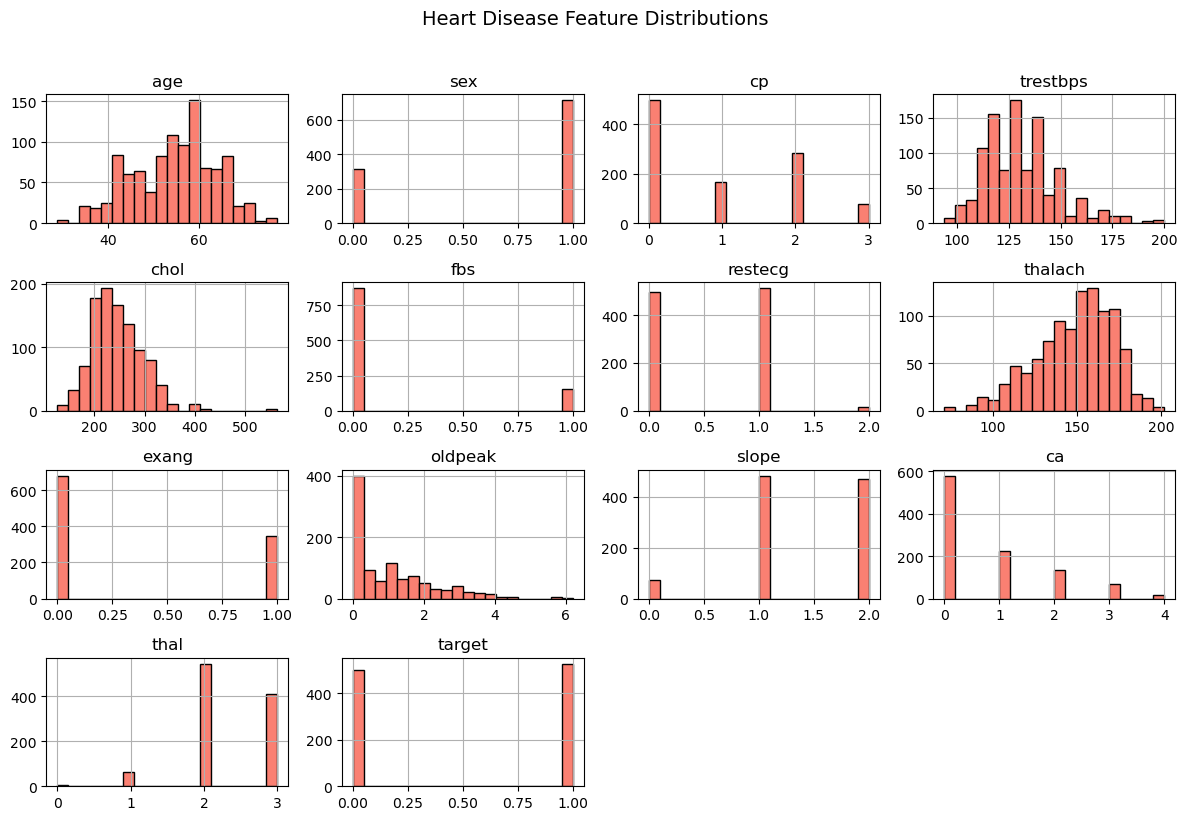

In [6]:
# Diabetes feature distributions
diabetes_df.hist(figsize=(12, 8), bins=20, color='steelblue', edgecolor='black')
plt.suptitle('Diabetes Feature Distributions', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/diabetes_distributions.png')
plt.show()

# Heart disease feature distributions
heart_df.hist(figsize=(12, 8), bins=20, color='salmon', edgecolor='black')
plt.suptitle('Heart Disease Feature Distributions', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/heart_distributions.png')
plt.show()

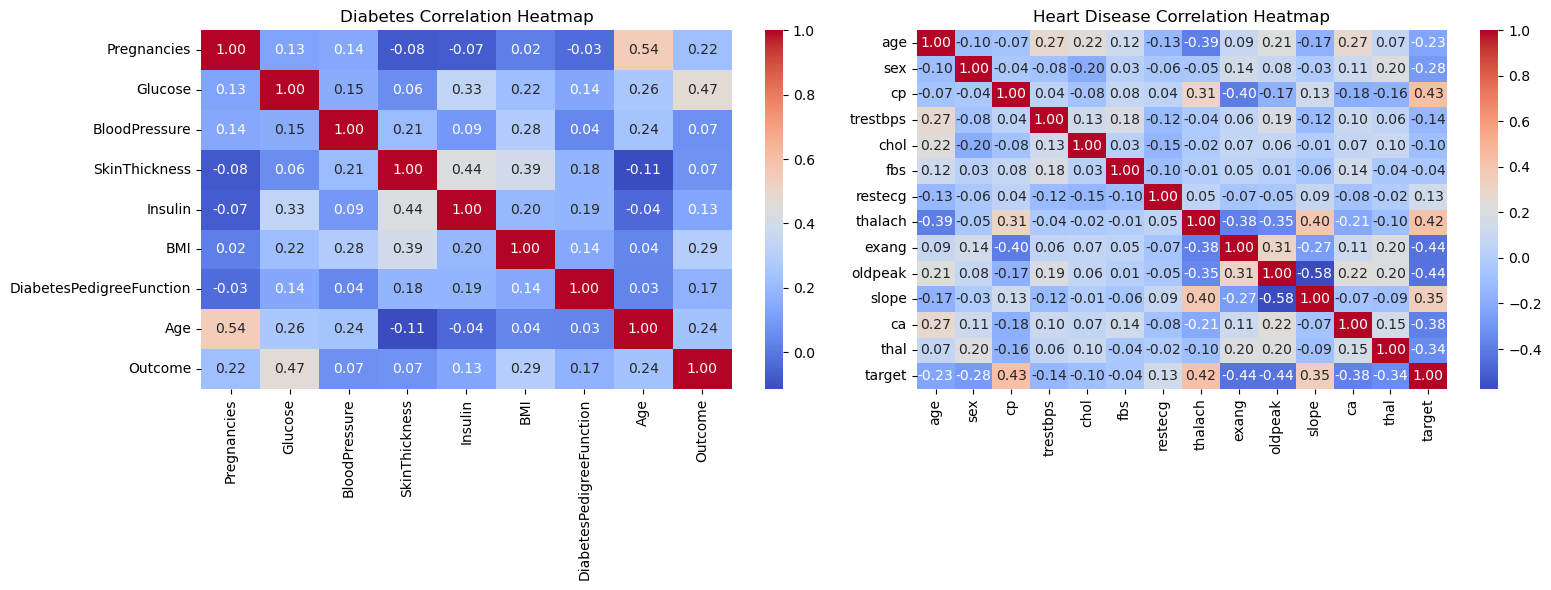

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(diabetes_df.corr(), annot=True, fmt='.2f', 
            cmap='coolwarm', ax=axes[0])
axes[0].set_title('Diabetes Correlation Heatmap')

sns.heatmap(heart_df.corr(), annot=True, fmt='.2f', 
            cmap='coolwarm', ax=axes[1])
axes[1].set_title('Heart Disease Correlation Heatmap')

plt.tight_layout()
plt.savefig('../results/figures/correlation_heatmaps.png')
plt.show()

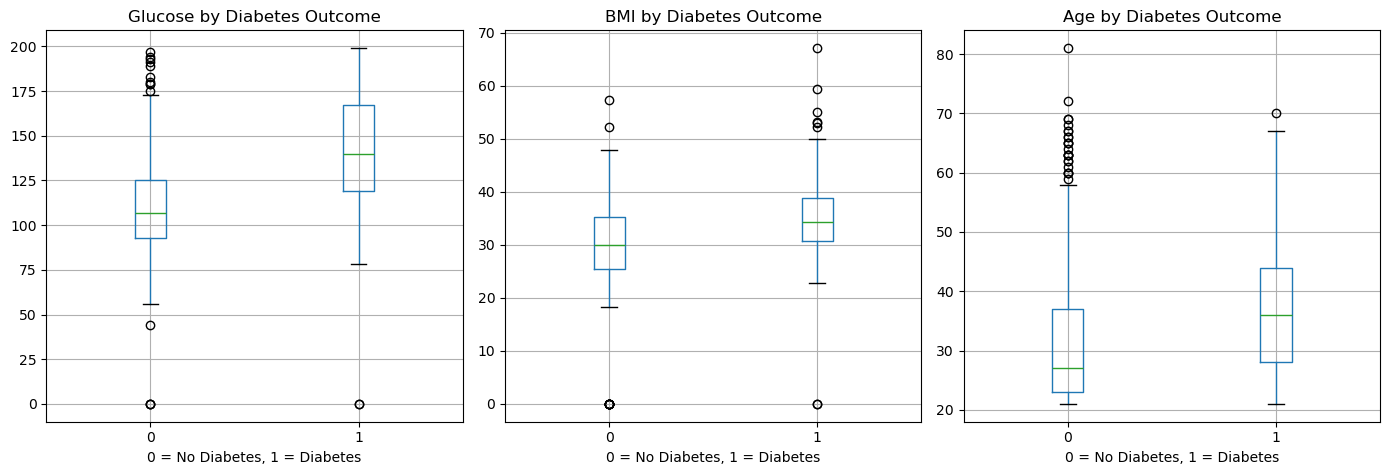

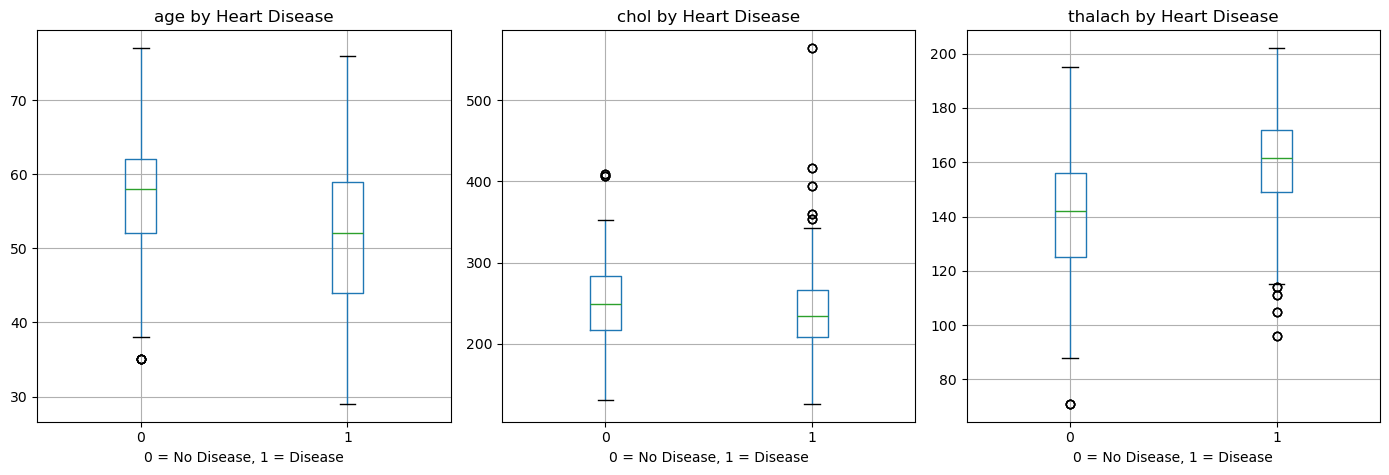

In [8]:
# Diabetes — key features vs Outcome
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, col in zip(axes, ['Glucose', 'BMI', 'Age']):
    diabetes_df.boxplot(column=col, by='Outcome', ax=ax)
    ax.set_title(f'{col} by Diabetes Outcome')
    ax.set_xlabel('0 = No Diabetes, 1 = Diabetes')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../results/figures/diabetes_boxplots.png')
plt.show()

# Heart — key features vs target
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, col in zip(axes, ['age', 'chol', 'thalach']):
    heart_df.boxplot(column=col, by='target', ax=ax)
    ax.set_title(f'{col} by Heart Disease')
    ax.set_xlabel('0 = No Disease, 1 = Disease')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../results/figures/heart_boxplots.png')
plt.show()